# B-8802B · validação do modelo sem temperatura

**O modelo sem temperatura** usa 4 sensores: vibrações dos mancais LA e LNA e pressões de sucção e descarga. A
temperatura do mancal LA sai do modelo e fica com o monitor (M8), que agora avisa **só quando o mancal esquenta** — um
mancal mais frio não indica falha. Mesma janela de treino do modelo atual (2025), mesma regra de alarme.

Bundle: `deploy_v2/Transpetro/B-8802B-2025/modelos/model_2025-01-01_2026-08-10_VAE_sem_temp/` (o atual continua na pasta
ao lado). Este notebook valida o modelo em três partes: a bateria (que agora conta o episódio de 10–12/01/2026 como
evento esperado), o catálogo de comportamentos e o monitor de temperatura.

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt, matplotlib.dates as mdates
%config InlineBackend.figure_format = "retina"
RAIZ = Path.cwd().resolve()
while not (RAIZ / "scripts").exists(): RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ / "src")); sys.path.insert(0, str(RAIZ / "scripts"))
from transpetro_modelos.drift import battery, monitor as mon
from transpetro_modelos.drift.residuo import ResidualLevelDetector
cat = pd.read_csv(RAIZ / "results/b8802b_v2/catalogo.csv")
bat = json.loads((RAIZ / "results/b8802b_vp_bateria/bateria.json").read_text())
B = battery.BATTERY["B-8802B-2025"]
NOVO = RAIZ / "deploy_v2/Transpetro/B-8802B-2025/modelos/model_2025-01-01_2026-08-10_VAE_sem_temp"
MODELOS = {"atual (5 sensores)": "#2a78d6", "sem temperatura (4)": "#1baf7a"}
TEXTO = "#52514e"
plt.rcParams.update({"font.size": 11})
def estilo(ax, t=None):
    if t: ax.set_title(t, loc="left", fontsize=12, fontweight="bold", color="#222222")
    ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.25, lw=0.5)

## 1. A bateria de aceitação

Os 12 modelos sem temperatura do retreino completo, mais o atual. A bateria agora trata o episódio de **10–12/01/2026**
como evento esperado (como o de 17/01): alertar nele não conta como alarme falso, e perdê-lo reprova.

In [2]:
linhas = []
for k, v in bat.items():
    linhas.append({"modelo": "ATUAL (5 sensores)" if k == "atual" else k, "aprovado": "sim" if v["approved"] else "não",
                   "alarme falso held-out (%)": round(v["fp_heldout_pct"], 3),
                   "10–12/01": "sim" if v["anchors"].get("ep1 10–12/01/26 vib LA+LNA") else "não",
                   "17/01": "sim" if v["anchors"].get("ep2 17/01/26 vib LA+LNA") else "não",
                   "falha 2022 (dias antes)": round(v["cross_era"]["lead_days"] or 0, 2),
                   "falha simulada 100% (h antes)": None if v["synthetic"].get("100") is None else round(v["synthetic"]["100"], 1),
                   "falha simulada 50% (h antes)": None if v["synthetic"].get("50") is None else round(v["synthetic"]["50"], 1)})
t = pd.DataFrame(linhas).set_index("modelo")
print(f"aprovados: {(t['aprovado'] == 'sim').sum() - (t.loc['ATUAL (5 sensores)', 'aprovado'] == 'sim')} de 12 sem temperatura; escolhido: l128-64-32_lat16_lr0.001_s2")
t

aprovados: 8 de 12 sem temperatura; escolhido: l128-64-32_lat16_lr0.001_s2


,aprovado,alarme falso held-out (%),10–12/01,17/01,falha 2022 (dias antes),falha simulada 100% (h antes),falha simulada 50% (h antes)
modelo,,,,,,,
ATUAL (5 sensores),não,0.000,não,sim,2.08,21.2,-0.3
l128-64-32_lat16_lr0.0001_s0,sim,0.000,sim,sim,2.08,22.4,11.2
l128-64-32_lat16_lr0.0001_s1,sim,0.000,sim,sim,2.08,21.2,3.4
l128-64-32_lat16_lr0.0001_s2,não,0.000,sim,não,2.08,22.1,7.3
l128-64-32_lat16_lr0.001_s0,não,0.000,não,não,1.34,NaN,NaN
l128-64-32_lat16_lr0.001_s1,sim,0.035,sim,sim,2.08,26.2,16.9
l128-64-32_lat16_lr0.001_s2,sim,0.000,sim,sim,2.08,25.6,16.5
l256-128-64_lat16_lr0.001_s0,não,0.000,sim,não,2.08,21.2,-6.7
l256-128-64_lat16_lr0.001_s1,sim,0.000,sim,sim,2.01,20.9,6.8


**Leitura:** 8 dos 12 modelos sem temperatura passam em tudo. O atual só reprova por não alertar em 10–12/01. O
escolhido (`l128-64-32 lr0.001 s2`) tem zero alarme falso fora dos episódios, falha de 2022 ~2,1 dias antes e a falha
simulada 26 h antes (16 h com meia intensidade).

## 2. O catálogo de comportamentos

**Verde** = fez o esperado (para "alerta": alertou na primeira semana); **laranja** = não fez; **cinza** = situação de
sensibilidade, sem resposta certa. As mudanças são aplicadas ao dado de 2025 (operação normal conhecida) de 01/09 a
31/10; sensor zerado e travado em 01/10/2025.

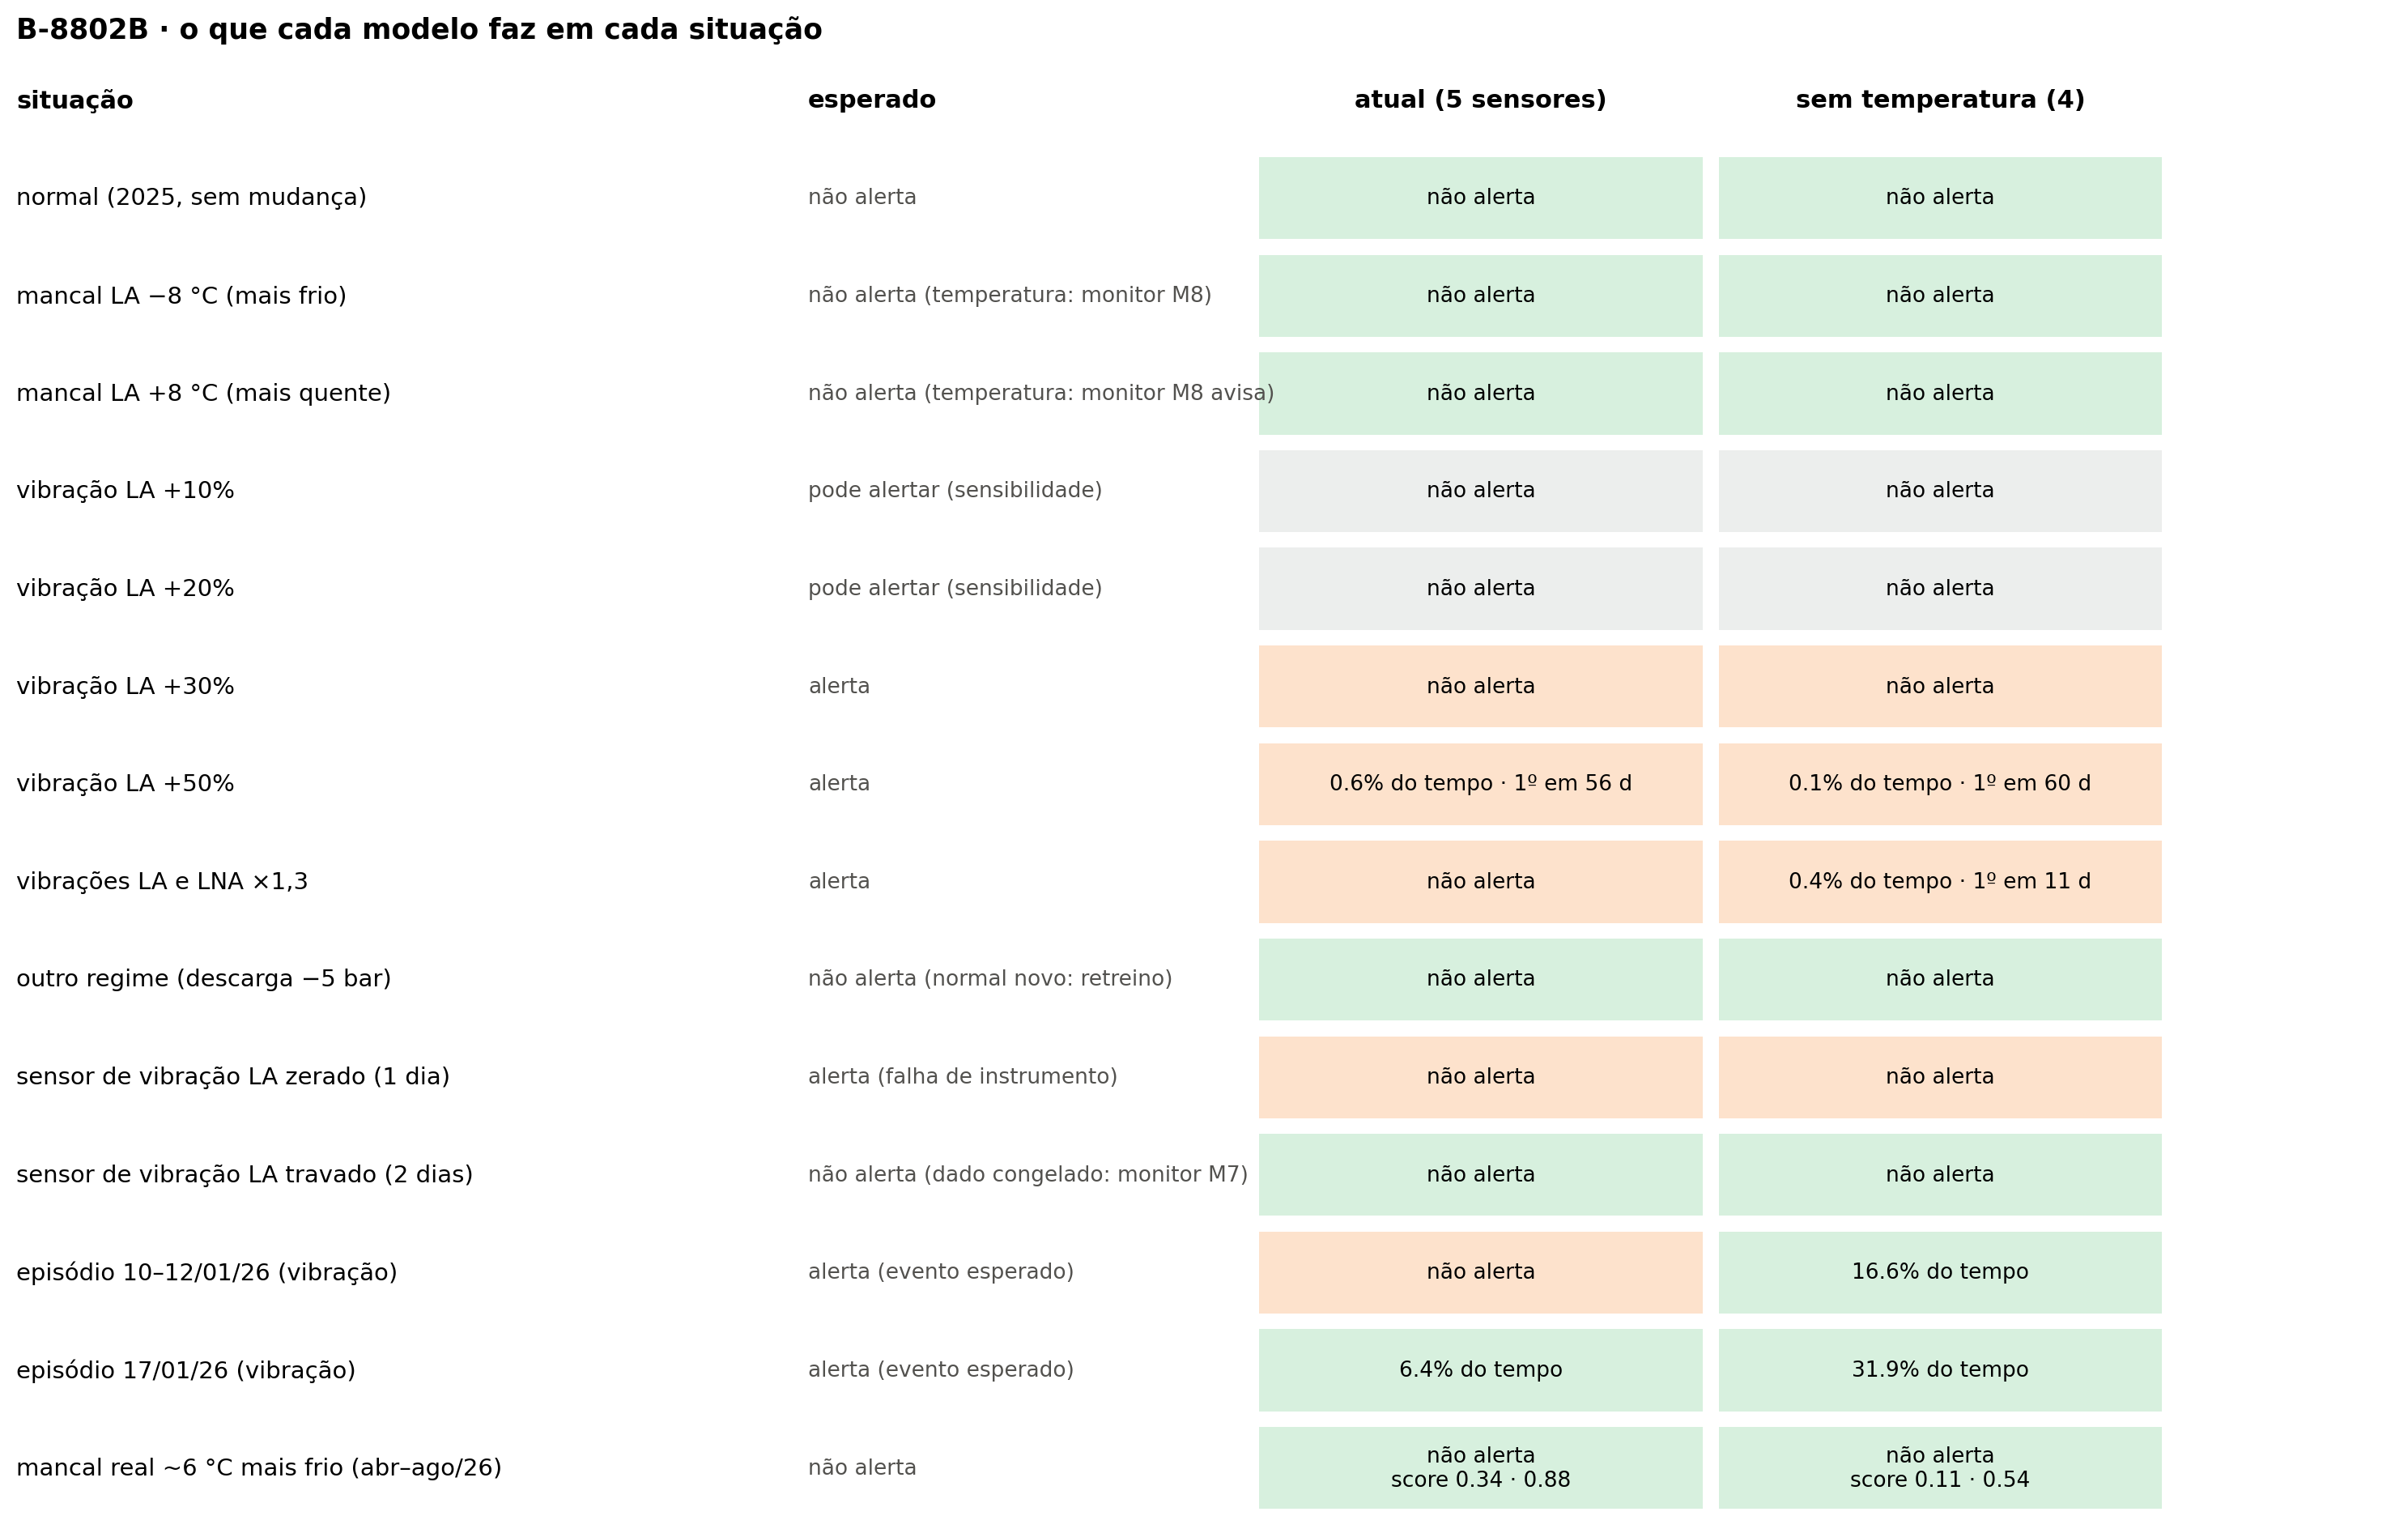

In [3]:
sit = cat[~cat["situação"].str.startswith("falha")].copy()
def avalia(r):
    p, e, h = r["% do tempo em alerta"], r["esperado"], r["1º alerta (h depois)"]
    if e.startswith("pode"): return "cinza"
    if e.startswith("alerta"): return "verde" if (p >= 0.3 and pd.notna(h) and h <= 168) else "laranja"
    return "verde" if p < 0.5 else "laranja"
def texto(r):
    if r["% do tempo em alerta"] < 0.05: return "não alerta"
    h = r["1º alerta (h depois)"]
    return f"{r['% do tempo em alerta']:.1f}% do tempo" + (f" · 1º em {h / 24:.0f} d" if pd.notna(h) and h >= 48 else "")
sit["ok"] = sit.apply(avalia, axis=1)
linhas = list(dict.fromkeys(sit["situação"]))
CORES_OK = {"verde": "#d7f0de", "laranja": "#fde2cc", "cinza": "#eceeed"}
fig, ax = plt.subplots(figsize=(15, 0.6 * len(linhas) + 1.2))
ax.set_xlim(0, 3); ax.set_ylim(len(linhas), -1); ax.axis("off")
ax.text(0, -0.5, "situação", fontweight="bold", va="center"); ax.text(1.0, -0.5, "esperado", fontweight="bold", va="center")
for j, m in enumerate(MODELOS):
    ax.text(1.85 + j * 0.58, -0.5, m, fontweight="bold", va="center", ha="center")
for i, s in enumerate(linhas):
    ax.text(0, i + 0.5, s, va="center", fontsize=10.5)
    ax.text(1.0, i + 0.5, sit[sit["situação"] == s]["esperado"].iloc[0], va="center", fontsize=9.5, color=TEXTO)
    for j, m in enumerate(MODELOS):
        r = sit[(sit["situação"] == s) & (sit["modelo"] == m)].iloc[0]
        ax.add_patch(plt.Rectangle((1.57 + j * 0.58, i + 0.08), 0.56, 0.84, color=CORES_OK[r["ok"]], lw=0))
        extra = f"\nscore {r['score ÷ limiar (mediana · p99)']}" if isinstance(r.get("score ÷ limiar (mediana · p99)"), str) else ""
        ax.text(1.85 + j * 0.58, i + 0.5, texto(r) + extra, va="center", ha="center", fontsize=9.5)
ax.set_title("B-8802B · o que cada modelo faz em cada situação", loc="left", fontsize=12.5, fontweight="bold")
fig.tight_layout()

## 3. A falha real e as falhas simuladas

Horas de antecedência: na falha real de 06/07/2022, antes da quebra; nas simuladas (assinatura de 2022, rampa de 48 h),
antes do fim da rampa. Em 01/08/2026 a bomba operou só 36% do tempo da rampa: essa data não vale como teste.

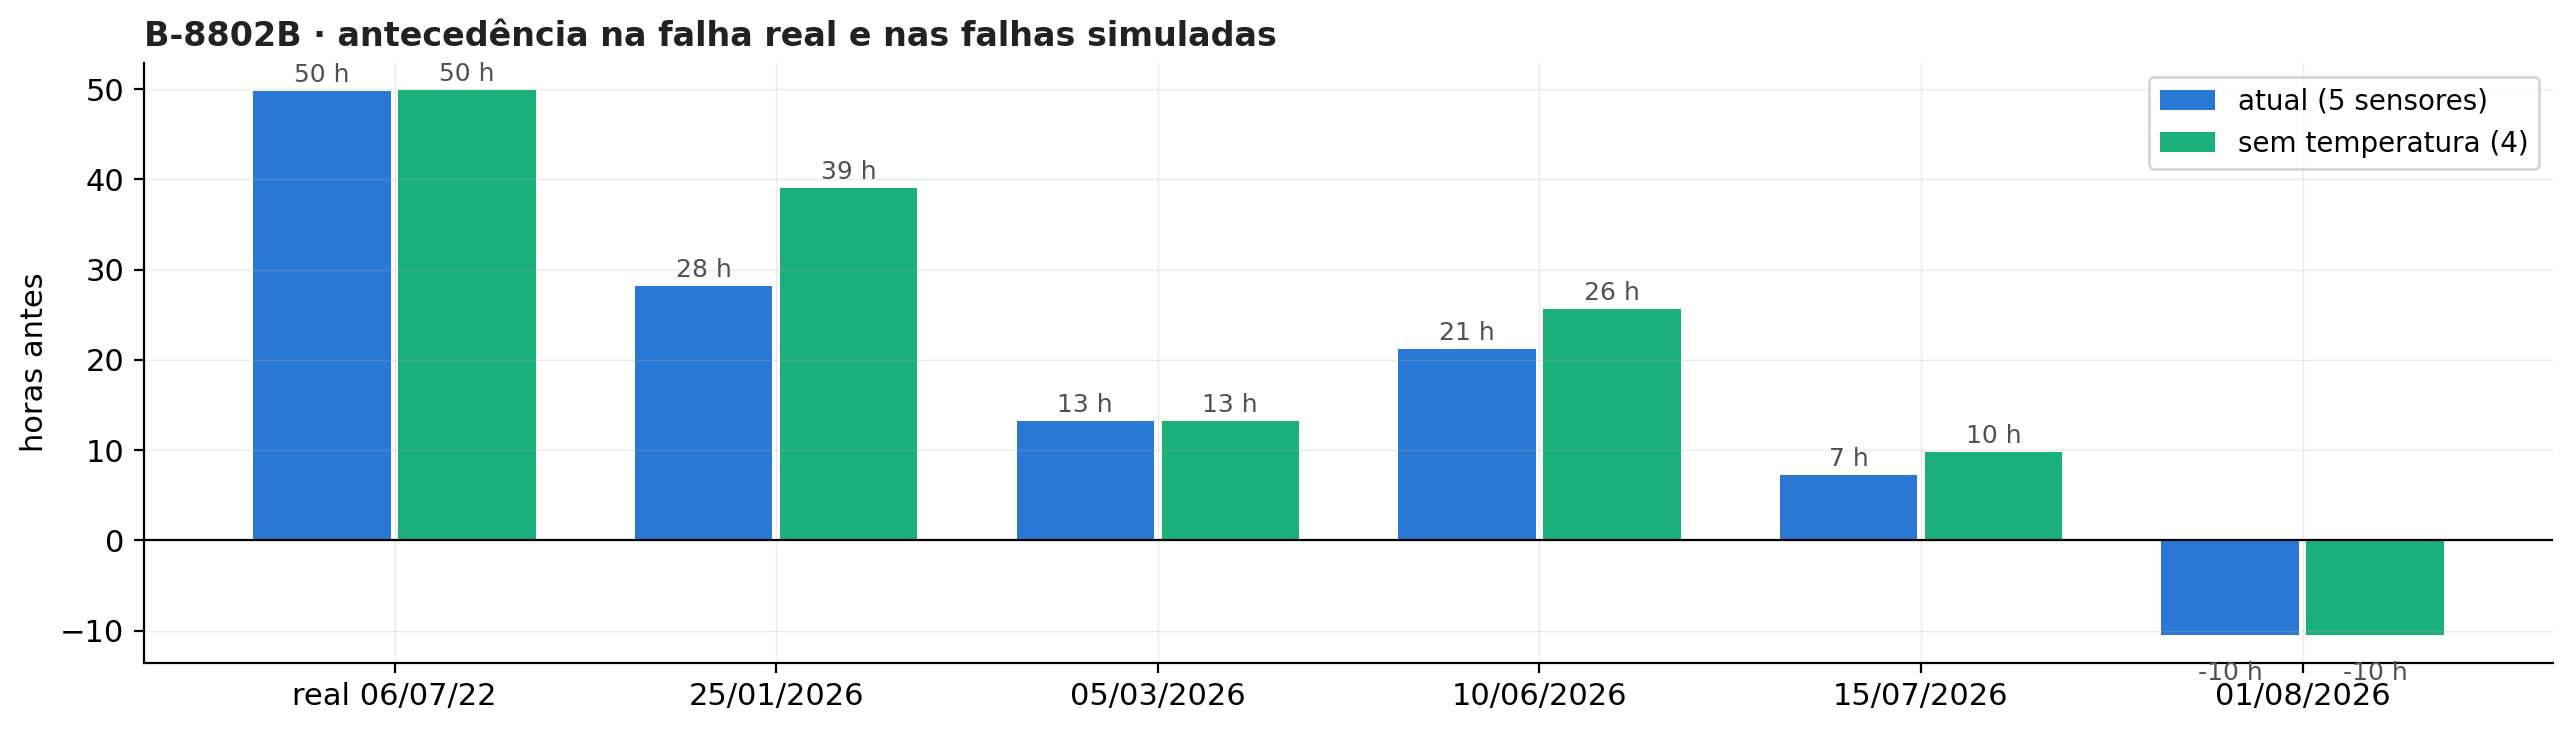

In [4]:
f = cat[cat["situação"].str.startswith("falha")].copy()
f["data"] = f["situação"].str.replace("falha simulada em ", "").str.replace("falha real de 06/07/2022", "real 06/07/22")
datas = list(dict.fromkeys(f["data"]))
fig, ax = plt.subplots(figsize=(13, 3.8))
for j, m in enumerate(MODELOS):
    d = f[f["modelo"] == m].set_index("data").reindex(datas)
    xs = np.arange(len(datas)) + (j - 0.5) * 0.38
    ax.bar(xs, d["antecedência (h)"].fillna(0), width=0.36, color=MODELOS[m], label=m)
    for x, v in zip(xs, d["antecedência (h)"]):
        ax.text(x, (v if pd.notna(v) else 0) + (1 if (pd.isna(v) or v >= 0) else -5), "—" if pd.isna(v) else f"{v:.0f} h",
                ha="center", fontsize=9, color=TEXTO)
ax.axhline(0, color="black", lw=0.8); ax.set_xticks(range(len(datas)), datas); ax.set_ylabel("horas antes")
ax.legend(fontsize=10); estilo(ax, "B-8802B · antecedência na falha real e nas falhas simuladas")
fig.tight_layout()

## 4. O monitor de temperatura (M8): só aquecimento

Antes, o M8 avisava quando o resíduo da temperatura do mancal LA (medido − esperado pela temperatura do motor e pelas
pressões) saía da faixa normal para **qualquer** lado. Desde o fim de março/2026 o mancal está ~6 °C mais frio que o
esperado e o M8 ficou amarelo. Agora ele vigia **só o lado de cima**.

,M8 'só acima' avisa
mancal mais quente (a partir de 01/10/2025),
+4 °C,não avisa
+6 °C,não avisa
+8 °C,em 2 dias
+10 °C,em 2 dias


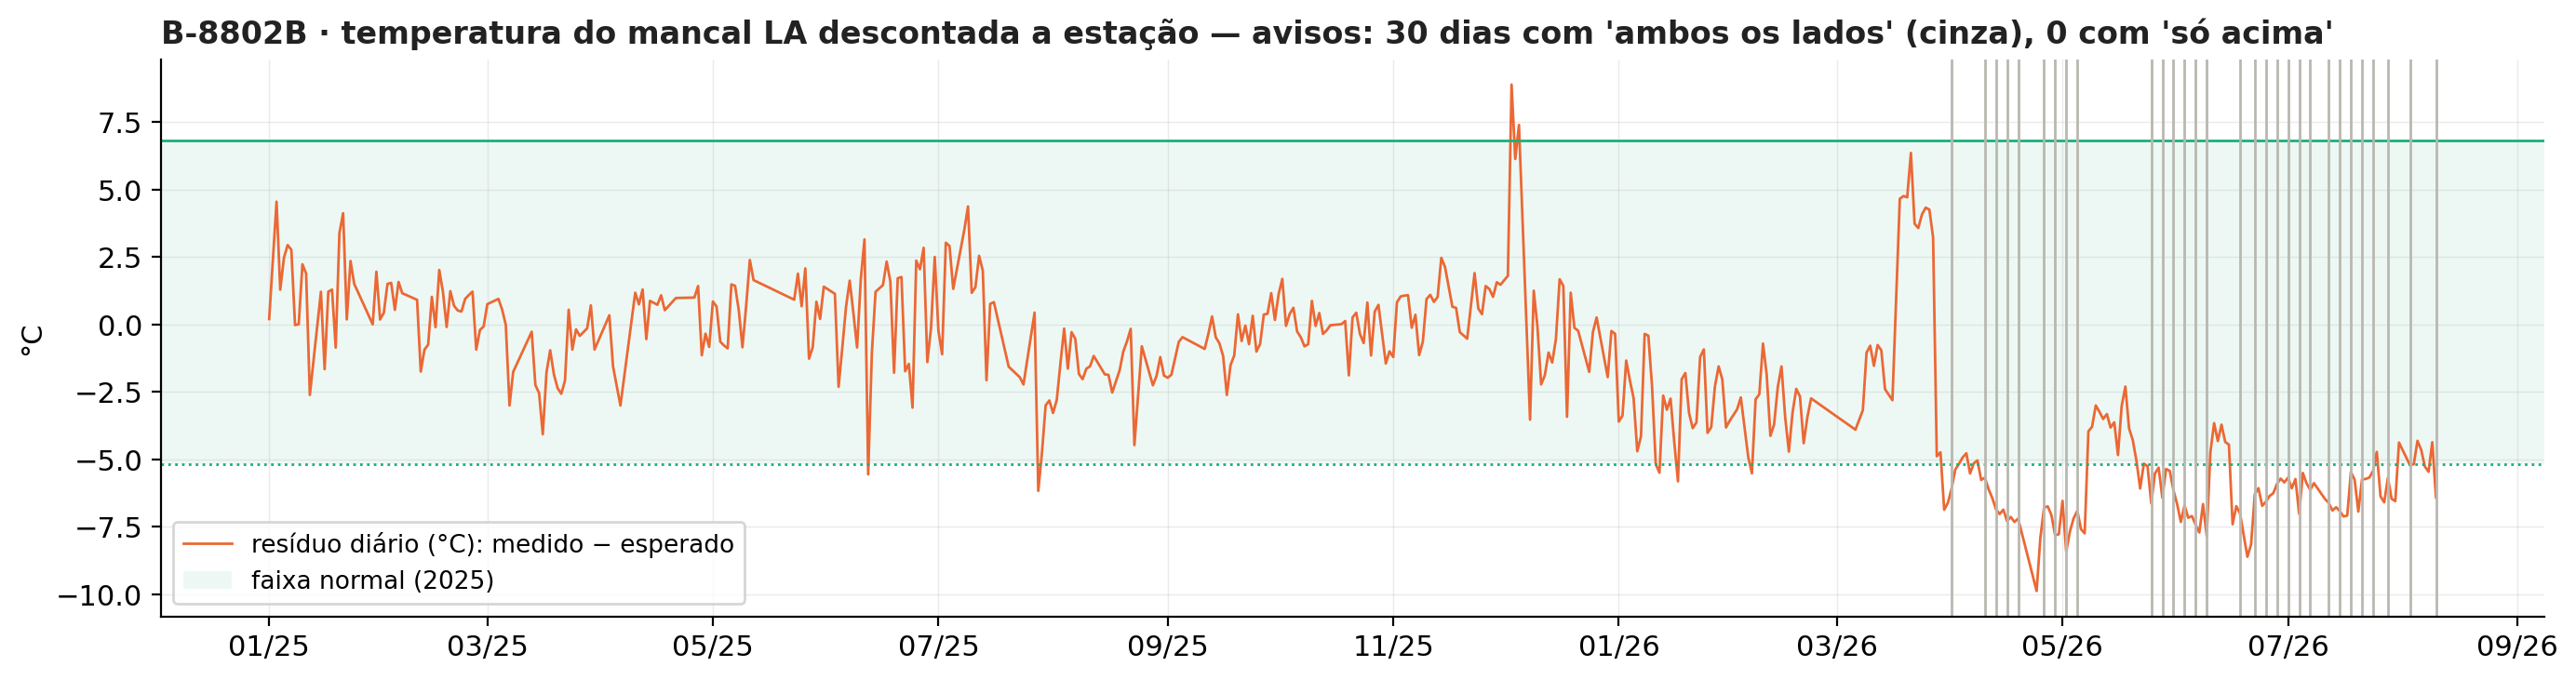

In [5]:
b = Path(B["bundle"]); raw = battery.si.carregar_dados(B["data_new"])
df = mon._sem_congelado(b, mon._temporal_steps(b, raw, todos_sensores=True))
d = json.loads((NOVO / "residual_ref.json").read_text())["detectors"][0]
det = ResidualLevelDetector.from_dict(d); r = det.daily(df); lo, hi = d["band"]
f_amb = det.__class__.from_dict(dict(d, lado="ambos")).scan(df)[1]; f_aci = det.__class__.from_dict(dict(d, lado="acima")).scan(df)[1]
fig, ax = plt.subplots(figsize=(14, 3.8))
ax.plot(r.index, r.values, color="#eb6834", lw=1, label="resíduo diário (°C): medido − esperado")
ax.axhspan(lo, hi, color="#1baf7a", alpha=0.08, lw=0, label="faixa normal (2025)")
ax.axhline(hi, color="#1baf7a", lw=1); ax.axhline(lo, color="#1baf7a", lw=1, ls=":")
for t in f_amb: ax.axvline(t, color="#b9b8b0", lw=1)
ax.set_ylabel("°C"); ax.legend(fontsize=9.5, loc="lower left"); ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%y"))
estilo(ax, f"B-8802B · temperatura do mancal LA descontada a estação — avisos: {len(f_amb)} dias com 'ambos os lados' (cinza), {len(f_aci)} com 'só acima'")
fig.tight_layout()

linhas = []
for ini in ["2025-10-01"]:
    for dT in (4, 6, 8, 10):
        x = df.copy(); m = (x.index >= ini) & (x.index < pd.Timestamp(ini) + pd.Timedelta(days=30)); x.loc[m, "Temperatura Bomba LA"] += dT
        fi = [t for t in det.__class__.from_dict(dict(d, lado="acima")).scan(x)[1] if t >= pd.Timestamp(ini)]
        linhas.append({"mancal mais quente (a partir de 01/10/2025)": f"+{dT} °C",
                       "M8 'só acima' avisa": f"em {(fi[0] - pd.Timestamp(ini)).days} dias" if fi else "não avisa"})
pd.DataFrame(linhas).set_index("mancal mais quente (a partir de 01/10/2025)")

## 5. Conclusões

**O modelo sem temperatura é igual ou melhor que o atual em tudo o que medimos:**
- **Falha real de 2022:** ~50 h antes nos dois.
- **Falhas simuladas:** igual ou antes (39 × 28 h, 26 × 21 h, 10 × 7 h, 13 × 13 h).
- **Mancal mais frio ou mais quente:** nenhum dos dois alerta; no mancal real mais frio de abr–ago/2026 o score do sem
  temperatura fica em 0,11 do limiar (o atual sobe para 0,34, com picos de 0,88).
- **Episódios de vibração de janeiro/2026:** o sem temperatura alerta nos dois; o atual, só em 17/01.
- **Bateria:** 8 dos 12 sem temperatura aprovados; o atual reprova só por perder 10–12/01.

**O monitor de temperatura (M8) passa a vigiar só aquecimento:** zero avisos pelo mancal frio de 2026 (eram 27 dias) e
um aquecimento de +8 °C acima do esperado é avisado em ~2 dias.

**Limites que valem para os dois modelos:**
- **Sensor de vibração zerado** não gera alerta: o pré-processamento corta o valor no mínimo visto no treino. Precisa de
  uma regra simples de instrumentação (vibração = 0 com a bomba operando).
- **Subida moderada de vibração** (+10% a +50% num mancal, ou +30% nos dois) é percebida tarde ou não é: o modelo reage
  a saltos como o da falha de 2022 (vibração LA de 2,5 para 3,8 mm/s em minutos). Um limite por sensor de vibração cobre
  esse caso.
- **Aquecimento de até ~+6 °C** acima do esperado fica dentro da faixa normal do M8.

**Para trocar em produção:** o bundle novo está pronto na pasta ao lado do atual. Segue o passo de sombra da política:
rodar os dois em paralelo por 4 semanas e trocar com o aval do time.